# Task 2.4: enlarge, measure, restore

This notebook follows the final report in order: **(a) derive the controls, (b) establish the trade-off, (c) specify one protocol, (d) test its improvement**. It reconstructs saved execution evidence without launching another quantum campaign. The main report is six pages; detailed circuit corrections and alternative pulses are supporting appendices.

The complete-cycle claim uses the ideal cubic two-mode model. The reference signal target is not a measured single-shot fidelity. See the dedicated Task 2.4 README for exact reproduction commands and AI-assistance disclosure.

In [1]:
from pathlib import Path
import sys, json, re, importlib.util
import numpy as np
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
if not (ROOT/'results/task_2_4.json').is_file():
    ROOT = ROOT.parent
assert (ROOT/'results/task_2_4.json').is_file()
sys.path.insert(0, str(ROOT))
spec = importlib.util.spec_from_file_location('final_synthesis', ROOT/'tools/synthesize_task_2_4.py')
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)
summary = json.loads(module.build().read_text())
local = json.loads((ROOT/'results/task_2_4.json').read_text())
report = (ROOT/'docs/task_2_4_final.md').read_text()
def report_section(start, end):
    text = report[report.index(start):report.index(end)]
    text = re.sub(r'!\[[^\n]*\]\([^\n]*\)(?:\{[^\n]*\})?', '', text)
    text = re.sub(r'\\Needspace\{[^\n]*\}', '', text)
    return text.strip()
print('Recomputed raw-trajectory information and recovered logical populations.')
print('Verified frozen cloud source records:', summary['frozen_cloud_source_records_verified'])
print('Indexed input files:', len(summary['source_files_sha256']))

Recomputed raw-trajectory information and recovered logical populations.
Verified frozen cloud source records: 66
Indexed input files: 118


In [2]:
display(Markdown(report_section('# Task 2.4(a):', '# Task 2.4(b):')))

# Task 2.4(a): derive the readout Hamiltonian

## Pumped circuit and two-photon exchange

With $\hbar=1$, the circuit Hamiltonian is

$$
H_{\rm circuit}=\omega_a a^\dagger a+\omega_b b^\dagger b
-2E_J\cos\varphi_\Sigma\cos(\hat\varphi+\varphi_\Delta),\qquad
\hat\varphi=\varphi_a(a+a^\dagger)+\varphi_b(b+b^\dagger).
$$

The operators $a$ and $b$ annihilate memory and buffer photons; $\varphi_a$ and $\varphi_b$ are their zero-point phases. At $\varphi_\Delta=\pi/2$ and $\varphi_\Sigma=-\pi/2+\epsilon_p\cos\omega_pt$, the identities $\cos(\hat\varphi+\pi/2)=-\sin\hat\varphi$ and $\cos\varphi_\Sigma\simeq\epsilon_p\cos\omega_pt$ give

$$
H_{\rm ATS}(t)\simeq2E_J\epsilon_p\cos\omega_pt
\left(\hat\varphi-\frac{\hat\varphi^3}{6}+\frac{\hat\varphi^5}{120}+\cdots\right).
$$

The mixed cubic contribution is

$$
H_{\rm ATS}^{(3)}\supset-E_J\epsilon_p\varphi_a^2\varphi_b\cos\omega_pt
(a+a^\dagger)^2(b+b^\dagger).
$$

Here $(a+a^\dagger)^2=a^2+a^{\dagger2}+2a^\dagger a+1$. In the rotating frame, $a^2b^\dagger$ acquires $e^{-i(2\omega_a-\omega_b)t}$. Choosing $\omega_p=2\omega_a-\omega_b$ cancels that rotation through one pump harmonic. The factor $1/2$ from the cosine gives

$$
H_{\rm ex}=g_2(a^2b^\dagger+a^{\dagger2}b),\qquad
|g_2|=\frac{E_J\epsilon_p\varphi_a^2\varphi_b}{2}.
$$

The printed pump phase gives negative exchange. We shift it by $\pi$ and use $g_2>0$ throughout. For $(\omega_a,\omega_b,\omega_p)/2\pi=(4.0,4.8,3.2)$ GHz, $E_J/2\pi=40$ GHz, $\varphi_a=0.06$ and $\varphi_b=0.30$, the rounded $\epsilon_p=0.035$ gives $|g_2|/2\pi=0.756$ MHz. Using $\epsilon_p=0.0353241$ gives the specified 0.763 MHz. These are illustrative circuit parameters [1,3].

## Separate microwave drives

The flux pump creates the exchange interaction. A separate resonant buffer microwave supplies $H_d=-\epsilon_d(b+b^\dagger)$ and sets $\alpha^2=\epsilon_d/g_2$. A further memory microwave port supplies the readout force. With the explicit laboratory phase convention

$$
H_{Z,\rm lab}=2\epsilon_Z(t)\cos(\omega_at-\phi)(a+a^\dagger),
$$

the resonant rotating-frame term is $H_Z=\epsilon_Z(t)(e^{i\phi}a^\dagger+e^{-i\phi}a)$. The discarded terms rotate at $2\omega_a$. A charge-coupled port realizes the same convention after a carrier-phase choice. All main calculations use $\phi=0$, giving

$$
\boxed{H=g_2(a^2b^\dagger+a^{\dagger2}b)-\epsilon_d(b+b^\dagger)
+\epsilon_Z(t)(a+a^\dagger).}
$$

The memory drive is therefore an explicitly added physical control, rather than an automatic consequence of the specified ATS pump.

## What else survives the expansion?

The first-order linear terms are off resonance at the supplied frequencies. Keeping the resonant exchange through fifth order gives

$$
\begin{aligned}
H_{\rm ex}^{(\le5)}={}&g_2[1-(\varphi_a^2+\varphi_b^2)/2]a^2b^\dagger\\
&-\frac{g_2\varphi_a^2}{3}a^\dagger a^3b^\dagger
-\frac{g_2\varphi_b^2}{2}a^2b^{\dagger2}b+\mathrm{h.c.}
\end{aligned}
$$

The last two terms still exchange two memory photons for one buffer photon, but their amplitudes depend on occupation. The first term includes the associated correction to the cubic coefficient. An odd sine potential gives no static Kerr term at first pump order. Off-resonant processes can generate frequency shifts and Kerr interactions at second pump order; those are effective corrections, not terms retained directly by the first-order rotating-wave approximation. Appendix A derives and tests the corrections separately from the primary cubic model.

# Task 2.4(b): establish the contrast-error trade-off

## Model and weak-drive response

We solve both modes, with time in µs and angular frequencies in $\mathrm{µs}^{-1}$:

$$
\dot\rho=-i[H,\rho]+\kappa_a\mathcal D[a]\rho+\kappa_b\mathcal D[b]\rho,
\qquad\mathcal D[c]\rho=c\rho c^\dagger-\tfrac12\{c^\dagger c,\rho\}.
$$

The supplied values are $g_2/2\pi=0.763$ MHz, $\kappa_b/2\pi=2.6$ MHz and $\kappa_a/2\pi=9.3$ kHz, with storage amplitude $\alpha=2.1$. Because $g_2/\kappa_b=0.2935$ and $\epsilon_d/\kappa_b=1.2942$, eliminating the buffer is not uniformly justified. Each simulation starts separately in $|+\alpha\rangle_a|0\rangle_b$ or $|-\alpha\rangle_a|0\rangle_b$.

For $A=\langle a\rangle$ and $B=\langle b\rangle$, factorization gives

$$
\dot A=-2ig_2A^*B-i\epsilon_Z-\kappa_a A/2,\qquad
\dot B=-i(g_2A^2-\epsilon_d)-\kappa_bB/2.
$$

Without memory loss or readout, $A=\pm\alpha$ and $B=0$: the buffer drive and conversion amplitude cancel. The readout force first moves the memory in its imaginary direction and disturbs that cancellation. Linearize around $A=s\alpha+\delta A$, $s=\pm1$. Neglecting loss and quadratic deviations, the settled memory equation is $0=-2ig_2s\alpha B_s-i\epsilon_Z$, hence

$$
\boxed{B_s\simeq-s\frac{\epsilon_Z}{2\alpha g_2},\qquad
C_b\equiv|B_+-B_-|\simeq\frac{|\epsilon_Z|}{\alpha g_2}.}
$$

Thus the buffer's real response has opposite signs for the two codewords. This is a weak-drive, post-settling approximation, before slow switching erases the initial-bit signal. It does not assume that the driven memory remains exactly at $\pm\alpha$.

## Executed drive sweep and rate definition

The full two-mode results at $\alpha=2.1$ are:

| $\epsilon_Z/g_2$ | Real-field contrast | $\dot{\mathcal I}$ ($\mathrm{µs}^{-1}$) | $\Gamma_X$ ($\mathrm{µs}^{-1}$) |
|--:|--:|--:|--:|
| 0.05 | 0.02379 | 0.009245 | $6.12\times10^{-6}$ |
| 0.10 | 0.04757 | 0.03697 | $2.37\times10^{-5}$ |
| 0.25 | 0.11885 | 0.2308 | $1.62\times10^{-4}$ |
| 0.50 | 0.23689 | 0.9167 | $9.24\times10^{-4}$ |
| 1.00 | 0.46037 | 3.462 | $8.61\times10^{-3}$ |

Contrast is the magnitude of the real separation of branch means over 3-4 µs, using $(N_a,N_b)=(32,12)$. The initial rate sweep uses $(28,10)$; its weak point becomes $6.105\times10^{-6}$ at $(32,12)$. The promoted protocol receives the larger-cutoff checks in Appendix B. All entries are backed by saved numerical outputs.

Here $\Gamma_X$ is the logical population-imbalance decay exponent used in Task 2.1. In a two-state model, $\Gamma_X=r_{01}+r_{10}$; each one-way rate equals $\Gamma_X/2$ only for symmetric switching. We identify a near-zero real Liouvillian mode that couples to the initial codeword difference and $\operatorname{Re}\langle a\rangle$. Independent time-domain cases check the method where decay is resolvable. This avoids fitting the drive's initial displacement as a bit flip; it does not provide a full-spectrum proof that no other relevant slower mode exists.





## Distinguish information, dephasing and bit flips

For $\Delta B=B_+-B_-$, define the ideal finite-time homodyne reference

$$
\mathcal I(T)=\eta\kappa_b\int_0^T
[\operatorname{Re}(e^{-i\vartheta}\Delta B)]^2dt,\qquad
\mathrm{SNR}^2=4\mathcal I.
$$

This uses unit white measurement noise, optimal temporal weighting and a fixed local-oscillator phase $\vartheta$; we use $\eta=1$. The equal target below is $\mathcal I=1$, corresponding to 15.9% ideal coherent-Gaussian classification error. It is a signal benchmark, not a demonstrated single-shot fidelity (Appendix B).

If the conditional emitted fields are coherent, their distinguishability causes an output-induced **coherence-decay exponent** $\gamma_{\rm coh,out}\simeq\kappa_b|\Delta B|^2/2$. This grows quadratically with weak readout strength even when neither logical branch switches. Under these assumptions it describes measurement dephasing, not $\Gamma_X$.

The additional bit-flip mechanism is excitation outside the stabilized manifold followed by relaxation into the other logical branch. Increasing the drive raises this disturbance as well as useful signal. Low final leakage alone cannot rule out a bit flip: leaked population may already have returned to the wrong branch. We therefore measure final wrong-logical population and leakage separately in an orthonormal cat basis, without postselection. Full definitions and the independent coherence checks are in Appendix B.

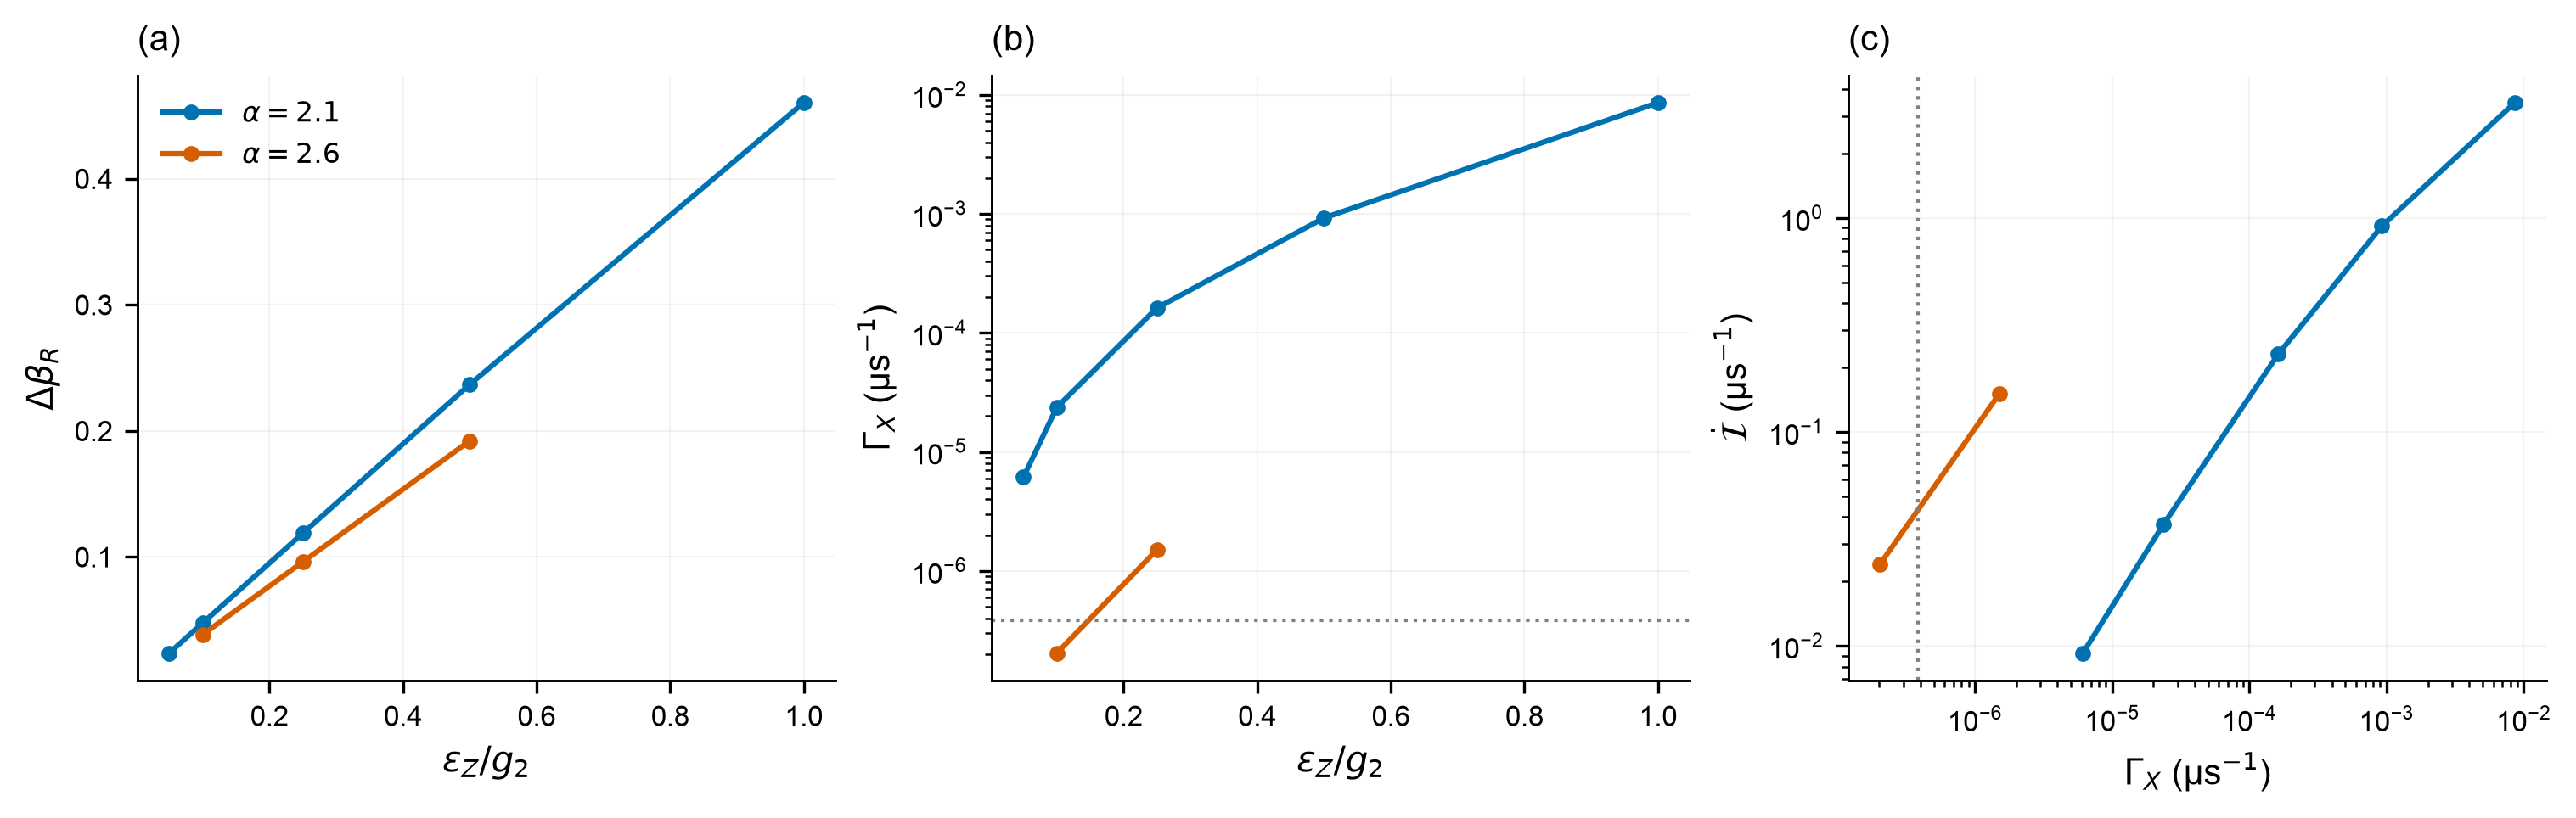

In [3]:
display(Markdown(report_section('# Task 2.4(b):', '# Task 2.4(c):')))
display(Image(filename=str(ROOT/'figures/task_2_4_tradeoff.png'), width=900))

# Task 2.4(c): propose and demonstrate one protocol

## Motivation and controls

A stronger drive at fixed $\alpha=2.1$ reads faster but increases logical relaxation. Larger cats suppress switching between the two logical branches, motivating **a temporary increase in their separation during readout** [2]. We test whether this permits a stronger force while retaining bit protection. Increasing $\alpha$ alone would weaken the field response; the stronger drive must compensate for that reduction.

Keep $g_2$ fixed and control the existing buffer microwave through $\epsilon_d(t)=g_2\alpha(t)^2$:

1. Enlarge $\alpha:2.1\to2.6$ over 2 µs, with memory readout off.
2. Apply $\epsilon_Z=0.1g_2$ and collect the buffer output for 41.3997 µs.
3. Turn off readout and restore $\alpha=2.1$ over 2 µs.
4. Wait 2 µs, then evaluate the original storage logical states.

Each ramp uses $s(u)=10u^3-15u^4+6u^5$, $0\le u\le1$. The complete cycle is **47.3997 µs**. We select this tested point because its estimated static $\Gamma_X$ is below the original idle-storage value. The readout target is $\mathcal I=1$; information emitted after the declared measurement interval is excluded from that target.

The reference uses $\alpha=2.1$, $\epsilon_Z=0.05g_2$ and the same 2-µs recovery. It needs 108.2205 µs of readout, or **110.2205 µs total**, to reach the same target. This is the specified weak reference, rather than an exhaustively optimized constant-drive benchmark.

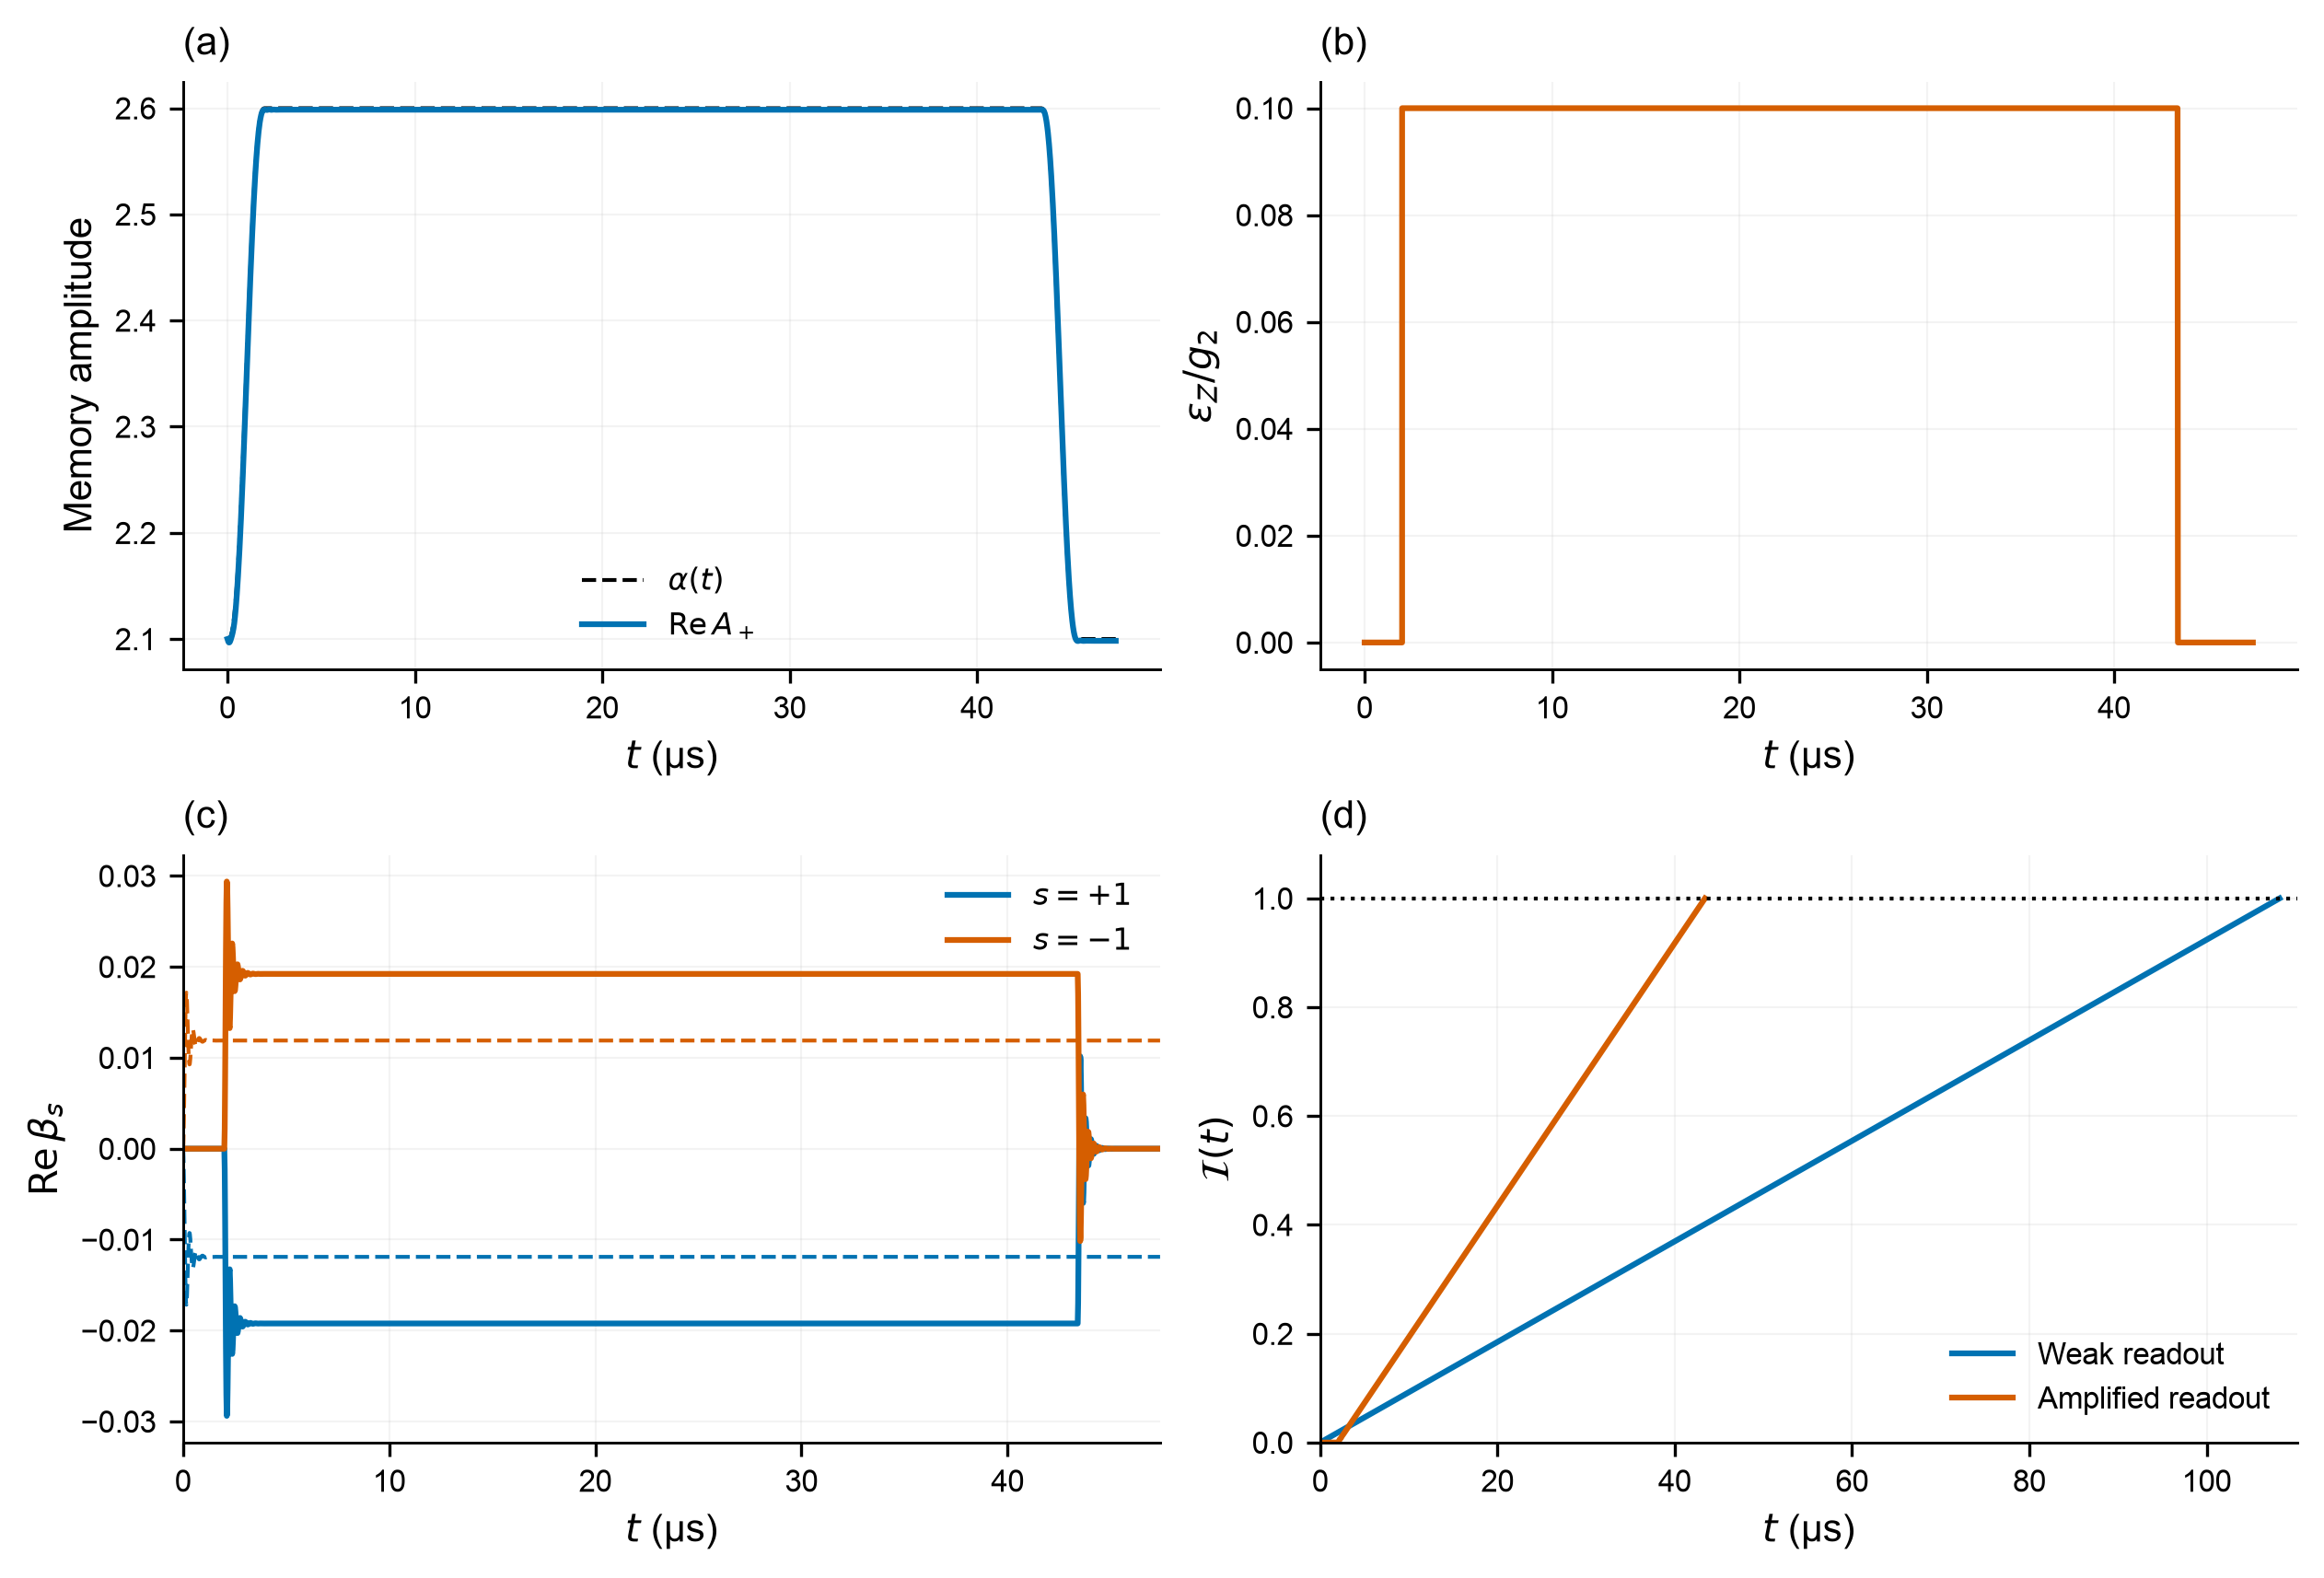

In [4]:
display(Markdown(report_section('# Task 2.4(c):', '# Task 2.4(d):')))
display(Image(filename=str(ROOT/'figures/task_2_4_protocol.png'), width=900))

In [5]:
display(Markdown(report_section('# Task 2.4(d):', r'\clearpage')))
base, selected = summary['cycles']['baseline'], summary['cycles']['amplified']
assert abs(base['recomputed_information']-1) < 1e-5
assert abs(selected['recomputed_information']-1) < 1e-5
assert summary['static_selected_mode']['gamma_x_per_us'] < local['storage_reference']['gamma_x_per_us']
rows = ['| Executed complete cycle | Total µs | Information | Final wrong population |',
        '|:--|--:|--:|--:|']
for label, m in [('Weak reference', base), ('Selected enlargement', selected)]:
    rows.append(f"| {label} | {m['cycle_duration_us']:.5f} | {m['recomputed_information']:.8f} | {max(m['recomputed_wrong_population']):.8g} |")
display(Markdown('\n'.join(rows)))
print('Actual complete-cycle speedup:', summary['comparisons']['conservative_cycle_speedup'])
print('Estimated static Gamma / undriven storage:', summary['comparisons']['conservative_gamma_over_idle'])

# Task 2.4(d): explain and validate the improvement

## Signal gain and retained protection

Doubling the memory force while increasing $\alpha$ by only 24% predicts a field gain $2(2.1/2.6)=1.615$. The full quantum value is 1.616. Its square predicts the information-rate gain, 2.61. This is the signal improvement; the independent rate calculation tests whether protection survives.

| Quantity | Weak reference | Selected enlargement cycle |
|:--|--:|--:|
| Readout contrast | 0.0237897 | 0.0384412 |
| Static $\Gamma_X$ ($\mathrm{µs}^{-1}$) | $6.1050\times10^{-6}$ | $2.0351\times10^{-7}$ |
| Information at measurement end | 1.0000000 | 0.9999925 |
| Complete-cycle time (µs) | 110.2205 | 47.3997 |
| Final wrong-logical population $p_X$ | $3.3063\times10^{-4}$ | $7.9483\times10^{-6}$ |
| Final code-space leakage | $8.110\times10^{-6}$ | $8.110\times10^{-6}$ |

Undriven storage has $\Gamma_X=3.8475\times10^{-7}\,\mathrm{µs}^{-1}$. The selected readout plateau is **0.529 times that value**. Direct integration of the entire return/recovery cycle, rather than a rate-times-duration estimate, gives the table's final $p_X$. The equal-clock idle control gives $9.0588\times10^{-6}$, compared with $7.9483\times10^{-6}$ for the protocol. That 12.3% difference is empirical: idle uses $(28,10)$ while the reported cycle uses $(38,16)$ (Appendix B).

The demonstrated conclusion is **2.33 times faster than the weak reference at the same ideal signal target, with a lower estimated plateau relaxation rate and a smaller recovered wrong-logical population**. A stronger fixed-size drive can be faster if its larger error cost is accepted. The data do not establish a global optimum at a common error budget.

## Numerical checks and physical limit

The final cycle-cutoff increment changes $p_X$ by 0.775%; tighter integration changes it by only $5.1\times10^{-14}$ in absolute probability. The last separate static-rate increments are 0.699% in memory cutoff and 0.530% in buffer cutoff; an earlier joint increment is 2.117%. These are empirical convergence checks, not rigorous infinite-dimensional error bars. Appendix B retains the full solver, spectral-loading and cutoff evidence.

The control also has costs. Enlarging the cat increases the leading photon-loss phase-dephasing scale by $2.6^2/2.1^2=1.53$ during readout. Final buffer population is small but nonzero, about $1.75\times10^{-5}$ photons. The protocol protects the stored computational bit; it does not preserve a superposition through measurement.

**The complete-cycle claim is for the ideal cubic two-mode model.** The circuit calculations establish higher-order terms and a separate compensated static feasibility test, but the full enlarged cycle has not been validated with those corrections. Mixed pump-microwave terms, bath dressing and device noise remain outside that test (Appendix A).

Fixed-size pulse tests are retained in Appendix C. They use different comparison conditions and are not part of the selected enlargement/read/restore protocol.

| Executed complete cycle | Total µs | Information | Final wrong population |
|:--|--:|--:|--:|
| Weak reference | 110.22051 | 1.00000000 | 0.00033062567 |
| Selected enlargement | 47.39966 | 0.99999246 | 7.9483413e-06 |

Actual complete-cycle speedup: 2.3253439958293867
Estimated static Gamma / undriven storage: 0.5289468404235262


## Supporting validation

The supplied(a-b) reference informed the clearer derivation, but its unverified numerical tables were not imported. The algebra and coherent-output normalization checks below are independent of the simulation Hamiltonian builders. The four pulse checks remain supporting evidence; they do not validate an unexecuted hybrid or the complete enlarged cycle with circuit corrections.

Laboratory drive-phase coefficient error: 1.962615573354719e-17
Fifth-order RWA matrix error /µs: 8.583756213050954e-13
Emitted coherent-state coherence-decay exponent: 0.25920000000002386
independent_validation pulse_b1f2b1393d0b0ff1 PASS
independent_validation pulse_6f787216b4e21a6d PASS
supplemental_cutoffs pulse_b1f2b1393d0b0ff1 PASS
supplemental_cutoffs pulse_6f787216b4e21a6d PASS


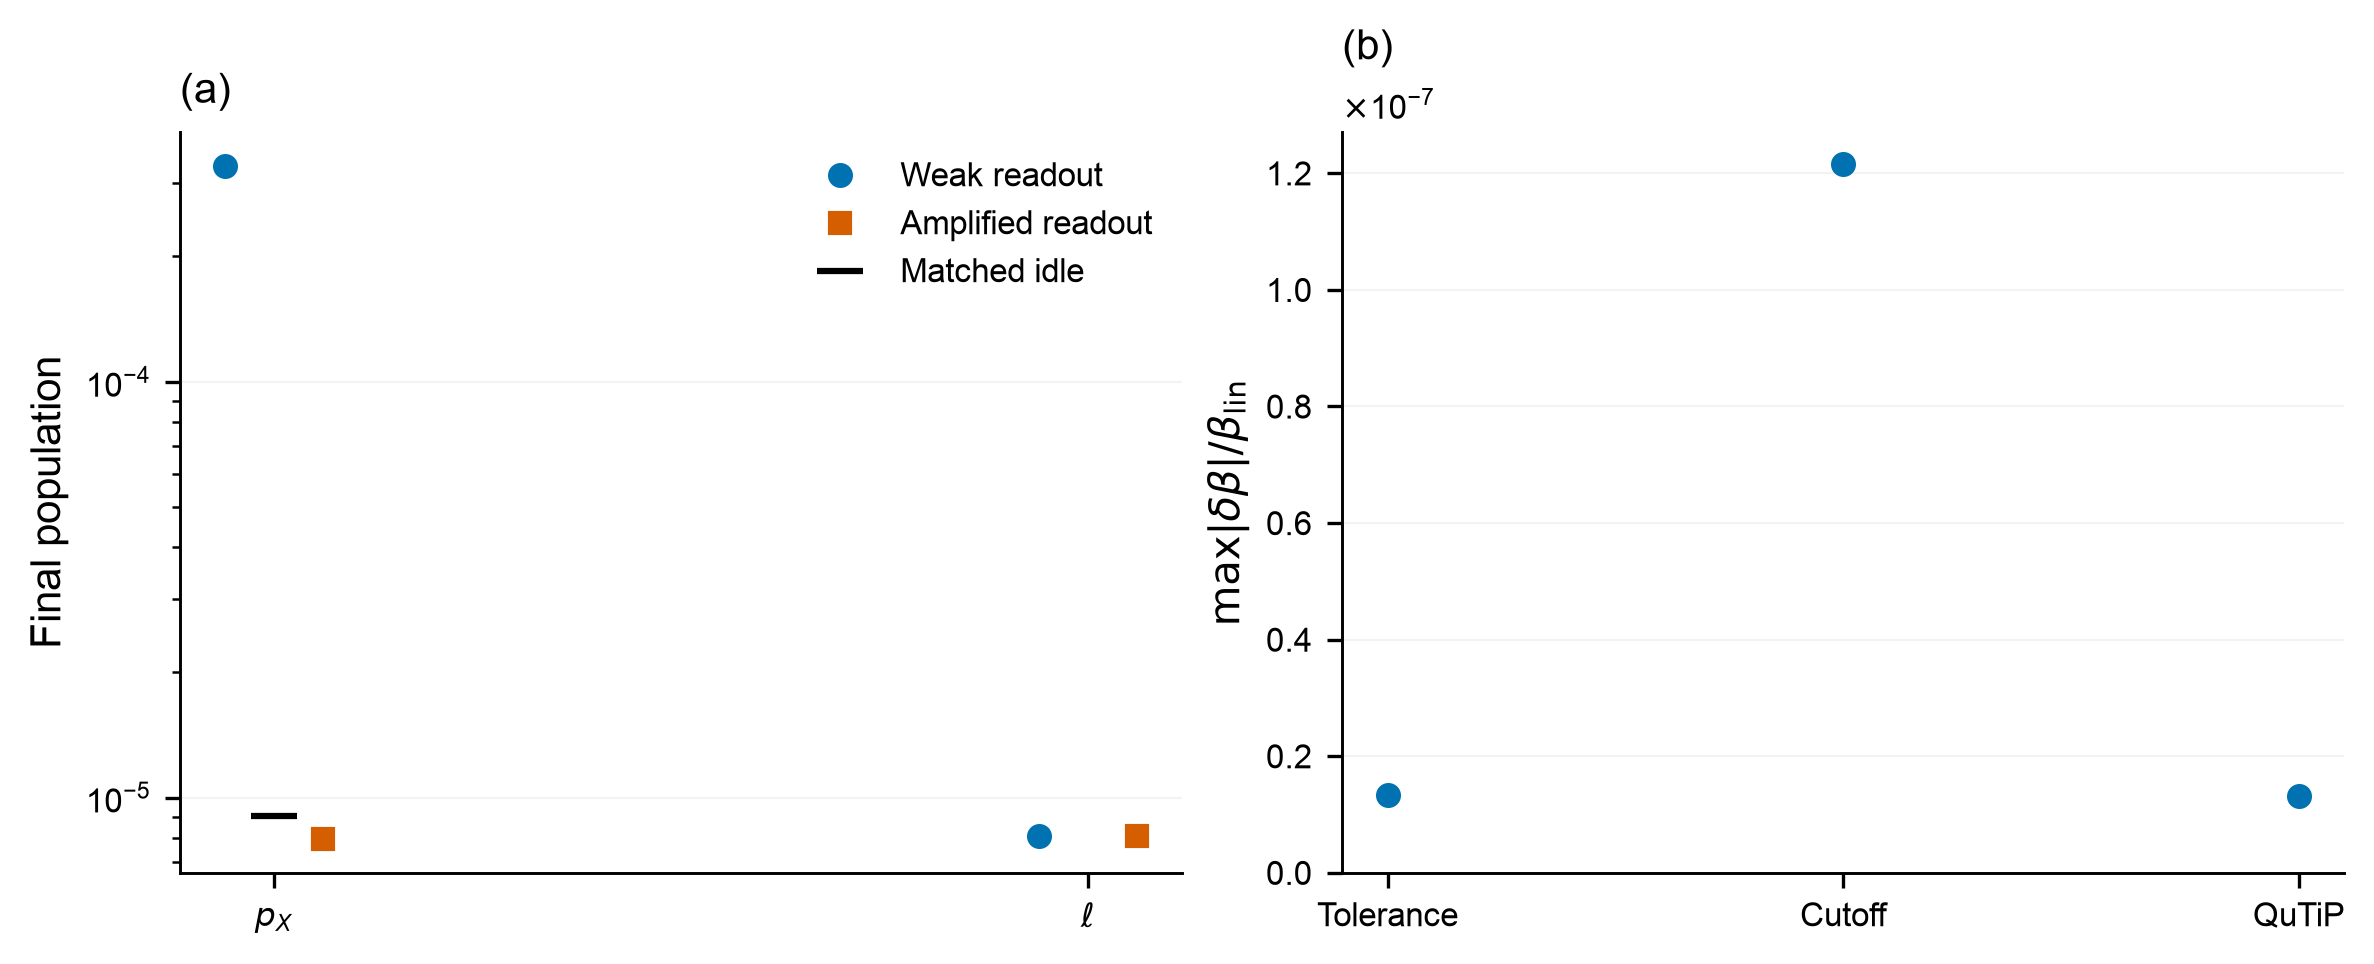

Complete corrected-circuit enlargement-cycle validation remains open.


In [6]:
checks = summary['independent_reference_checks']
assert checks['all_checks_pass']
print('Laboratory drive-phase coefficient error:', checks['creation_coefficient_error'])
print('Fifth-order RWA matrix error /µs:', checks['fifth_order_rwa_low_fock_max_error_per_us'])
print('Emitted coherent-state coherence-decay exponent:', checks['coherent_output_decay_exponent_per_us'])
for check in summary['campaign']['independent_and_supplemental_checks']:
    assert check['validation_passed']
    print(check['kind'], Path(check['source']).stem, 'PASS')
display(Image(filename=str(ROOT/'figures/task_2_4_validation.png'), width=900))
print('Complete corrected-circuit enlargement-cycle validation remains open.')

## Files and disclosure

`docs/task_2_4_final.md` is the canonical report source. Its appendices retain complete logical-state definitions, measurement convention, cutoff checks, circuit sensitivity, optional controls and negative findings. `docs/task_2_4_README.md` links the final PDF, original detailed notebook 09, code, results and reproduction instructions. The evidence index preserves input SHA256 hashes and original execution identities.

AI assisted with derivation, implementation, execution, checks and editing. The submitting team remains responsible for explaining and defending the results. No experimental or human scientific approval is implied.